# SpaceX Classification Model Comparison

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay
X=pd.read_csv("dataset_part_3.csv").fillna(0);y=pd.read_csv("dataset_part_2.csv").Class
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)

In [3]:
models={"Logistic Regression":(Pipeline([("scale",StandardScaler()),("model",LogisticRegression(max_iter=2000))]),{"model__C":[.01,.1,1,10]}),"SVM":(Pipeline([("scale",StandardScaler()),("model",SVC())]),{"model__C":[.1,1,10],"model__kernel":["linear","rbf"]}),"Decision Tree":(DecisionTreeClassifier(random_state=42),{"max_depth":[2,3,4,5,None],"min_samples_leaf":[1,2,4]}),"KNN":(Pipeline([("scale",StandardScaler()),("model",KNeighborsClassifier())]),{"model__n_neighbors":[3,5,7,9]})}
results=[];fitted={}
for name,(model,grid) in models.items():
 search=GridSearchCV(model,grid,cv=StratifiedKFold(5,shuffle=True,random_state=42),scoring="accuracy",n_jobs=-1);search.fit(X_train,y_train)
 score=accuracy_score(y_test,search.predict(X_test));results.append({"Model":name,"CV accuracy":search.best_score_,"Test accuracy":score,"Best params":str(search.best_params_) });fitted[name]=search.best_estimator_
results=pd.DataFrame(results).sort_values("CV accuracy",ascending=False);display(results);results.to_csv("model_comparison_recomputed.csv",index=False)

,Model,CV accuracy,Test accuracy,Best params
1,SVM,0.875238,0.833333,"{'model__C': 1, 'model__kernel': 'rbf'}"
3,KNN,0.847619,0.777778,{'model__n_neighbors': 3}
2,Decision Tree,0.845714,0.777778,"{'max_depth': 2, 'min_samples_leaf': 1}"
0,Logistic Regression,0.834286,0.777778,{'model__C': 0.01}


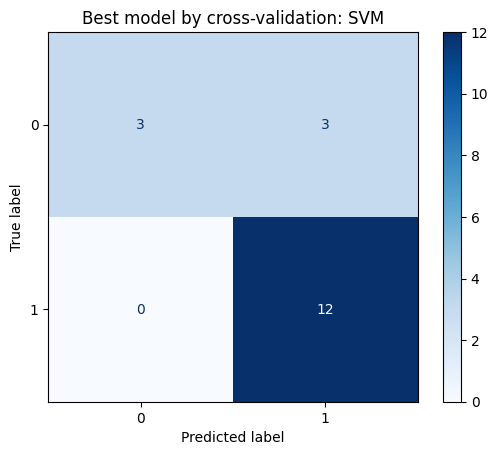

Selected model: SVM


In [4]:
best_name=results.iloc[0].Model;best=fitted[best_name]
ConfusionMatrixDisplay.from_predictions(y_test,best.predict(X_test),cmap="Blues");plt.title("Best model by cross-validation: "+best_name);plt.show()
print("Selected model:",best_name)